# FL-BENCH-004.3 — SCAFFOLD

*Epic EPIC-001 · story fl_bench_004 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Implement SCAFFOLD (option II control variates) and evaluate under partial participation.

## 2. Scientific background
Control variates correct client drift [karimireddy2020]; communication doubles.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does the implementation satisfy its validation identities?
- **RQ2.** How does it behave under IID vs non-IID data?

## 4. Hypotheses
- **H1.** Validation identities hold to numerical precision.

## 5. Mathematical formulation
y ← y − η(g − c_i + c); c_i⁺ = c_i − c + (x − y)/(Kη); invariant c = mean(c_i) under full participation.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_bench_004"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_bench_004


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`fl.py`, `stats.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
parts = partition_dirichlet(data.y_train, 8, 0.3, SEED)
r = run_fl(FLConfig(algo="scaffold", rounds=6, local_epochs=2, mu=0.05, seed=SEED), data, parts)
print("scaffold final", {k: round(v, 4) for k, v in r.final.items() if isinstance(v, float)}, "comm MB", round(r.totals["comm_mb"], 3))
assert np.isfinite(r.w).all()

scaffold final {'round_time_s': 0.073, 'agg_time_s': 0.0003, 'client_time_s': 0.0727, 'client_time_max_s': 0.0317, 'acc': 0.8306, 'loss': 0.3944, 'precision': 0.7476, 'recall': 0.871, 'f1': 0.8046, 'specificity': 0.8035, 'auc': 0.9154, 'diverged': 0.0} comm MB 1.009


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-BENCH-004.3` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_4_3_runs.csv')
show_csv('task_4_3_partial_participation.csv')

,algo,condition,clients,seed,local_epochs,participation,mu,rounds,acc,precision,recall,f1,auc,loss,specificity,rounds_to_target,comm_mb,comm_mb_per_round,train_wall_s,cpu_time_s,rss_peak_mb,skew,pr_auc,ece
0,fedavg,dir0.1,10,0,5,1.0,0.0,30,0.8675,0.9508,0.7072,0.8111,0.9571,3.537000e-01,0.9754,18.0,3.154,0.1051,19.3791,19.26,731.2422,0.4587,0.9404,0.0962
1,fedavg,dir0.1,10,1,5,1.0,0.0,30,0.8281,0.9621,0.5960,0.7360,0.9402,4.017000e-01,0.9842,NaN,3.154,0.1051,19.5297,19.44,731.2422,0.5014,0.9216,0.1335
2,fedavg,dir0.1,10,2,5,1.0,0.0,30,0.8675,0.9146,0.7396,0.8179,0.9450,3.180000e-01,0.9535,23.0,3.154,0.1051,18.7871,18.66,731.2422,0.3983,0.9256,0.0635
3,fedavg,dir0.1,10,3,5,1.0,0.0,30,0.8117,0.8913,0.6057,0.7212,0.9043,4.110000e-01,0.9503,NaN,3.154,0.1051,20.7111,20.56,731.2422,0.3510,0.8747,0.0739
4,fedavg,dir0.1,10,4,5,1.0,0.0,30,0.8347,0.9278,0.6388,0.7566,0.9317,4.391000e-01,0.9665,NaN,3.154,0.1051,19.4499,19.35,731.2422,0.4753,0.9081,0.1153
5,scaffold,dir0.1,10,0,5,1.0,0.0,30,0.8825,0.8334,0.8847,0.8583,0.9533,3.265000e-01,0.8810,17.0,6.308,0.2103,17.7503,17.64,731.2422,0.4587,0.9363,0.0540
6,scaffold,dir0.1,10,1,5,1.0,0.0,30,0.8792,0.8113,0.9116,0.8585,0.9526,3.260000e-01,0.8573,10.0,6.308,0.2103,18.3047,18.14,731.2422,0.5014,0.9373,0.0663
7,scaffold,dir0.1,10,2,5,1.0,0.0,30,0.9019,0.9029,0.8474,0.8742,0.9607,2.644000e-01,0.9387,10.0,6.308,0.2103,19.9975,19.93,731.2422,0.3983,0.9421,0.0281
8,scaffold,dir0.1,10,3,5,1.0,0.0,30,0.4333,0.4132,0.9738,0.5802,0.5217,2.736847e+05,0.0697,NaN,6.308,0.2103,19.6333,19.45,731.2422,0.3510,0.4130,0.5561
9,scaffold,dir0.1,10,4,5,1.0,0.0,30,0.6467,0.6310,0.2928,0.4000,0.5888,1.012273e+08,0.8848,NaN,6.308,0.2103,18.8040,18.71,731.2461,0.4753,0.4692,0.0689


,algo,participation,seed,acc,f1
0,fedavg,0.3,0,0.8214,0.8128
1,fedavg,0.3,1,0.8781,0.8387
2,fedavg,0.3,2,0.7156,0.7344
3,scaffold,0.3,0,0.6725,0.6970
4,scaffold,0.3,1,0.8422,0.8122
5,scaffold,0.3,2,0.8128,0.8020


## 12. Metrics collection
Metric definitions: accuracy, F1, rounds-to-target (acc≥0.85), logical communication MB, local drift ||w_k − w_t||.

In [8]:
show_csv('task_4_3_summary.csv')

,algo,acc,acc_ci,f1,f1_ci,comm_mb,comm_mb_ci,train_wall_s,train_wall_s_ci
0,fedavg,0.8419,"[0.811, 0.8727]",0.7686,"[0.7142, 0.823]",3.154,"[3.154, 3.154]",19.5714,"[18.7, 20.44]"
1,scaffold,0.7487,"[0.494, 1.003]",0.7143,"[0.448, 0.9805]",6.308,"[6.308, 6.308]",18.8980,"[17.75, 20.05]"


## 13. Statistical analysis
Seeds are the unit of replication; paired tests across seeds (Wilcoxon signed-rank, paired t), Holm correction, Cohen's d_z; see task 4.6.

In [9]:
show_csv('task_4_3_summary.csv', 30)

,algo,acc,acc_ci,f1,f1_ci,comm_mb,comm_mb_ci,train_wall_s,train_wall_s_ci
0,fedavg,0.8419,"[0.811, 0.8727]",0.7686,"[0.7142, 0.823]",3.154,"[3.154, 3.154]",19.5714,"[18.7, 20.44]"
1,scaffold,0.7487,"[0.494, 1.003]",0.7143,"[0.448, 0.9805]",6.308,"[6.308, 6.308]",18.8980,"[17.75, 20.05]"


## 14. Visualizations

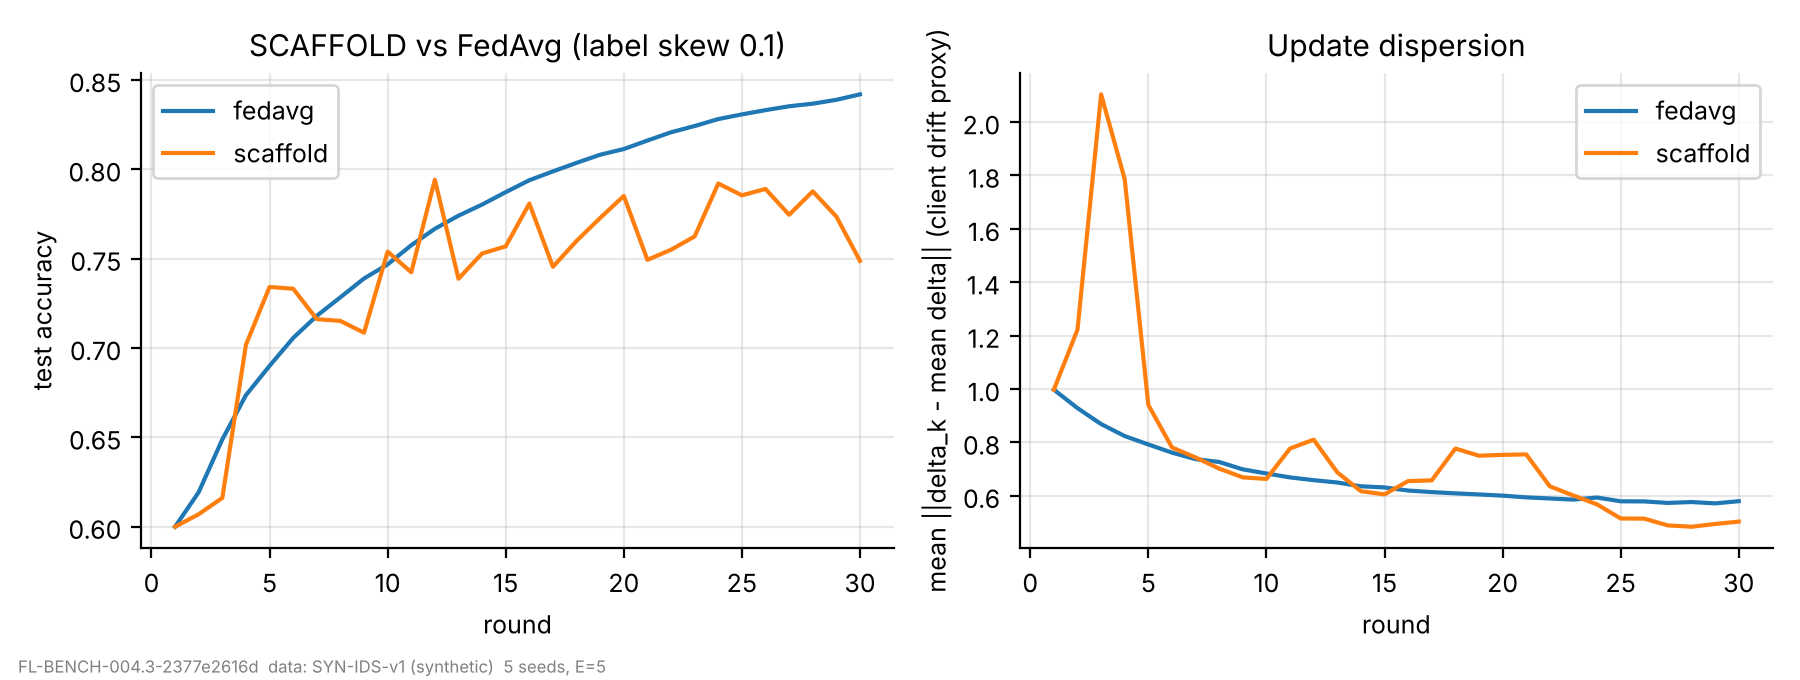

In [10]:
show_fig('task_4_3_scaffold.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Communication is exactly 2× FedAvg; control-variate invariant verified.

In [11]:
show_csv('task_4_3_partial_participation.csv')

,algo,participation,seed,acc,f1
0,fedavg,0.3,0,0.8214,0.8128
1,fedavg,0.3,1,0.8781,0.8387
2,fedavg,0.3,2,0.7156,0.7344
3,scaffold,0.3,0,0.6725,0.6970
4,scaffold,0.3,1,0.8422,0.8122
5,scaffold,0.3,2,0.8128,0.8020


## 16. Limitations
- Synthetic tabular data; small MLP.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Implementation validated by identity tests (tests/ and task JSON).

**Jira acceptance:** see `docs/fl_bench_004/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`mcmahan2017`, `li2020fedprox`, `karimireddy2020`, `wang2020fednova`, `li2021niid` — details in `docs/fl_bench_004/references.md`.